# Neural Network Training with Backpropagation

This notebook demonstrates the implementation of a simple neural network with one hidden layer to solve the XOR problem. It includes the following steps:
- Initialization of parameters (weights and biases)
- Forward propagation to compute activations
- Loss computation using binary cross-entropy
- Backpropagation to calculate gradients
- Parameter updates using gradient descent

The training process is visualized by plotting the loss over epochs, and the final predictions of the network are displayed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T
d = np.array([0, 1, 1, 0])

print(X.shape)
print(d.shape)

(2, 4)
(4,)


In [3]:
def initialize_parameters(seed = 0):
    """
    Initializes the weights and biases for a simple neural network with one hidden layer.
    """
    np.random.seed(seed)
    W1 = np.random.rand(2, 2) - 0.5
    b1 = np.zeros((2, 1))
    W2 = np.random.rand(1, 2) - 0.5
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2


In [4]:
def sigmoid(z):
    """
    Computes the sigmoid activation function.
    """
    return 1 / (1 + np.exp(-z))

In [5]:
def forward(X, W1, b1, W2, b2):
    """
    Calculate the weighted sum and adds the bias for each layer, then applies the sigmoid activation function.
    1. Calculate Z1 = W1 @ X + b1
    2. Apply the sigmoid activation function to Z1 to get A1.
    3. Calculate Z2 = W2 @ A1 + b2
    4. Apply the sigmoid activation function to Z2 to get A2.
    """
    Z1 = np.dot(W1, X) + b1
    A1 = sigmoid(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = sigmoid(Z2)
    return Z1, A1, Z2, A2

In [6]:
def compute_loss(d, A2):
    """
    Computes the binary cross-entropy loss.
    """
    A2 = np.clip(A2, 1e-12, 1 - 1e-12)
    return (-1 / d.size) * np.sum(d * np.log(A2) + (1 - d) * np.log(1 - A2))

In [7]:
def backprop(X, d, W2, A1, A2):
    """
    Computes the gradients of the loss with respect to the weights and biases using backpropagation.
    1. Calculate the error at the output layer: dz2 = A2 - d
    2. Compute the gradients for the second layer: dW2 and db2. 
    3. Calculate the error at the hidden layer: dz1 = (W2.T @ dz2) * A1 * (1 - A1)
    4. Compute the gradients for the first layer: dW1 and db1.
    5. Return the gradients: dW1, db1, dW2, db2.
    """
    m = X.shape[1]
    dz2 = A2 - d
    dW2 = dz2 @ A1.T / m
    db2 = np.sum(dz2, axis=1, keepdims=True) / m
    dz1 = (W2.T @ dz2) * A1 * (1 - A1)
    dW1 = dz1 @ X.T / m
    db1 = np.sum(dz1, axis=1, keepdims=True) / m
    
    return dW1, db1, dW2, db2

In [8]:
def update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, lr):
    """
    Updates the weights and biases using gradient descent.
    1. Update W1 and b1 using the gradients dW1 and db1.
    2. Update W2 and b2 using the gradients dW2 and db2
    3. Return the updated weights and biases.
    """
    return W1 - lr * dW1, b1 - lr * db1, W2 - lr * dW2, b2 - lr * db2


In [9]:
lr = 1
epochs = 10000
W1, b1, W2, b2 = initialize_parameters()
losses = []

In [10]:
for i in range(epochs):
    Z1, A1, Z2, A2 = forward(X, W1, b1, W2, b2)
    loss = compute_loss(d, A2)
    dW1, db1, dW2, db2 = backprop(X, d, W2, A1, A2)
    W1, b1, W2, b2 = update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, lr)

    losses.append(loss)
    
    if i % 1000 == 0:
        print(f"Epoch {i}, Loss: {loss}")

Epoch 0, Loss: 0.6933012085805277
Epoch 1000, Loss: 0.6931461481548901
Epoch 2000, Loss: 0.6931404161386509
Epoch 3000, Loss: 0.6928499003903332
Epoch 4000, Loss: 0.02117273879401103
Epoch 5000, Loss: 0.006668500617387284
Epoch 6000, Loss: 0.003914938056049977
Epoch 7000, Loss: 0.002762856952546473
Epoch 8000, Loss: 0.0021319986668680868
Epoch 9000, Loss: 0.0017345091789318


In [11]:
_, _, _, A2 = forward(X, W1, b1, W2, b2)
print("Predictions:", A2.round(3))
print("Classes:    ", (A2 > 0.5).astype(int))
print("Labels:     ", d)

Predictions: [[0.002 0.999 0.999 0.001]]
Classes:     [[0 1 1 0]]
Labels:      [0 1 1 0]


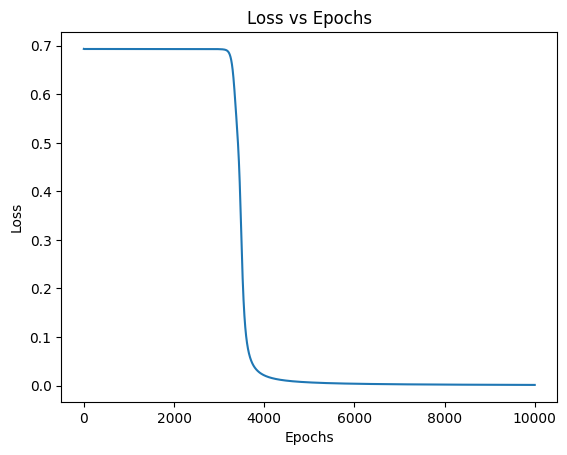

In [12]:
plt.plot(range(epochs), losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss vs Epochs')
plt.show()